Data loaded successfully. Shape: (9094, 16)

Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9094 entries, 0 to 9093
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Id               9094 non-null   object 
 1   Date             9094 non-null   object 
 2   Player           9094 non-null   object 
 3   PlyID            9094 non-null   int64  
 4   Team             9094 non-null   object 
 5   Opponent         9094 non-null   object 
 6   Competition      9094 non-null   object 
 7   Manager          9094 non-null   object 
 8   Team.Possession  9094 non-null   float64
 9   Team.Goals       9094 non-null   int64  
 10  Opponent.Goals   9094 non-null   int64  
 11  WinProb          9094 non-null   float64
 12  Minutes          9094 non-null   int64  
 13  HmAw             9094 non-null   object 
 14  PlyPosition      9094 non-null   object 
 15  Shots            9094 non-null   int64  
dtypes: f

Id                 0
Date               0
Player             0
PlyID              0
Team               0
Opponent           0
Competition        0
Manager            0
Team.Possession    0
Team.Goals         0
dtype: int64


Sample Data:


,Id,Date,Player,PlyID,Team,Opponent,Competition,Manager,Team.Possession,Team.Goals,Opponent.Goals,WinProb,Minutes,HmAw,PlyPosition,Shots
0,74_18282,2020-01-21,Pepe Reina,74,Aston Villa,Watford,EPL,Dean Smith,0.64,2,1,0.340,95,home,GK,0
1,74_18308,2020-02-16,Pepe Reina,74,Aston Villa,Tottenham,EPL,Dean Smith,0.54,2,3,0.237,95,home,GK,0
2,74_18293,2020-02-01,Pepe Reina,74,Aston Villa,Bournemouth,EPL,Dean Smith,0.60,1,2,0.287,94,away,GK,0
3,74_18279,2020-01-18,Pepe Reina,74,Aston Villa,Brighton,EPL,Dean Smith,0.45,1,1,0.190,95,away,GK,0
4,74_18314,2020-02-22,Pepe Reina,74,Aston Villa,Southampton,EPL,Dean Smith,0.54,0,2,0.190,95,away,GK,0


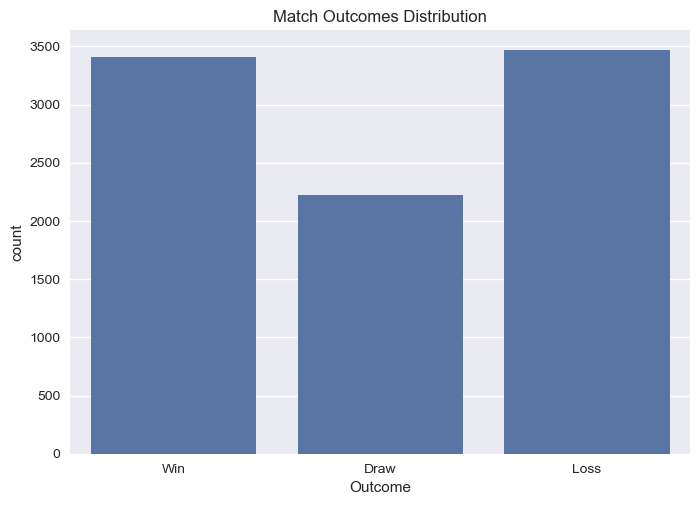


Analysis 1: Shots by Position


,sum,mean,count
PlyPosition,,,
FW,1843,2.140534,861
MC,965,0.815034,1184
Sub,754,0.396842,1900
DC,710,0.474916,1495
AMC,427,1.558394,274
FWL,383,2.349693,163
FWR,352,2.159509,163
AML,290,1.870968,155
MR,281,1.206009,233


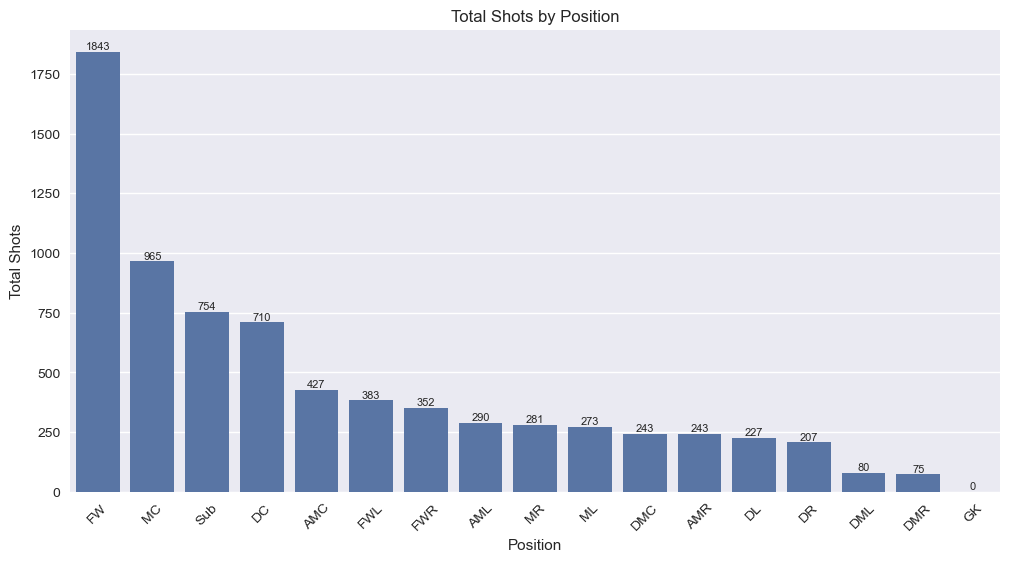


Analysis 2: Possession vs Shots


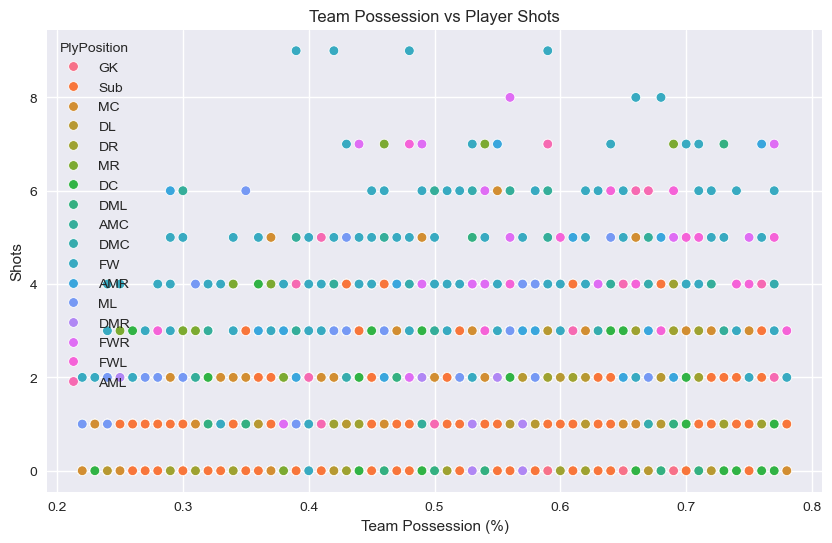


Correlation between Possession and Shots:


,Team.Possession,Shots
Team.Possession,1.000000,0.155892
Shots,0.155892,1.000000


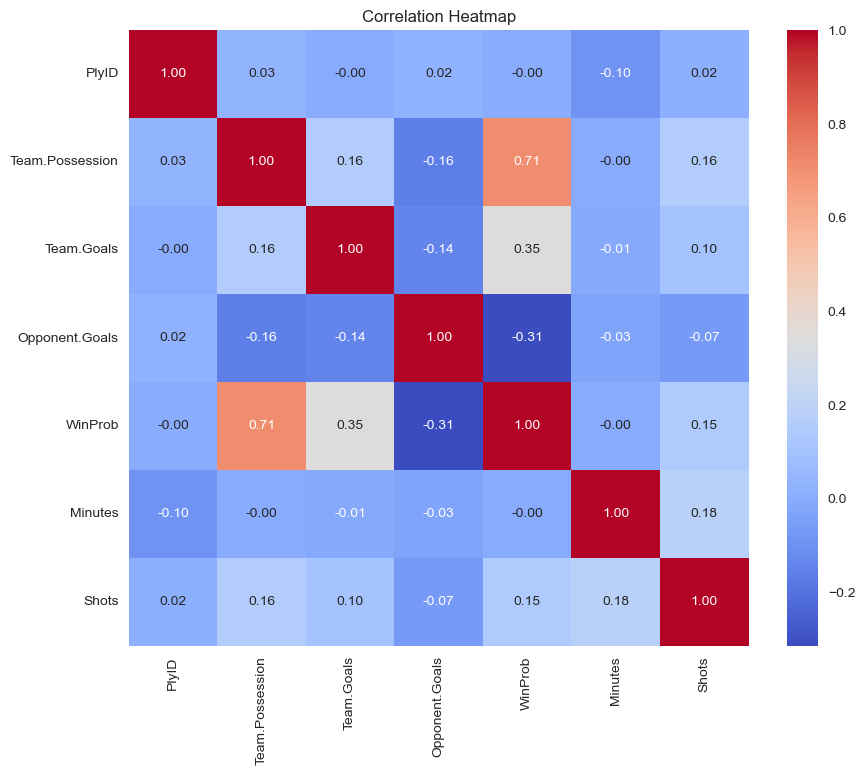

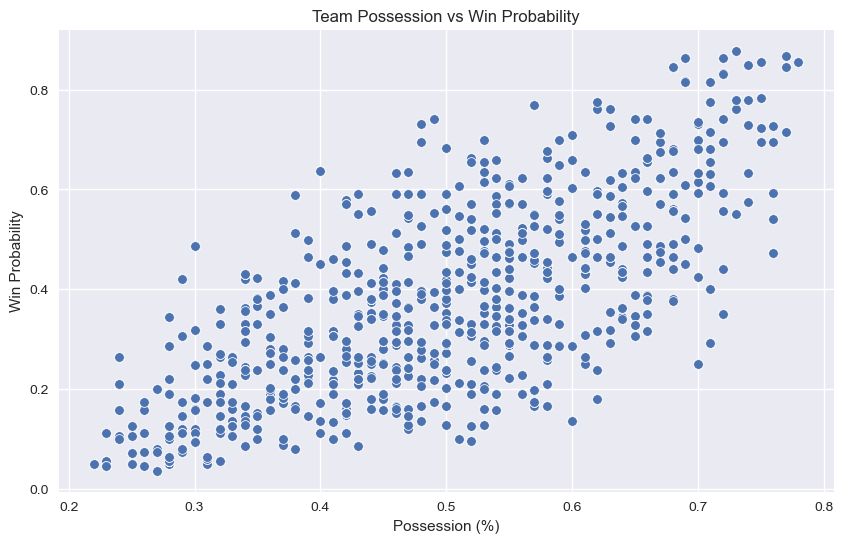

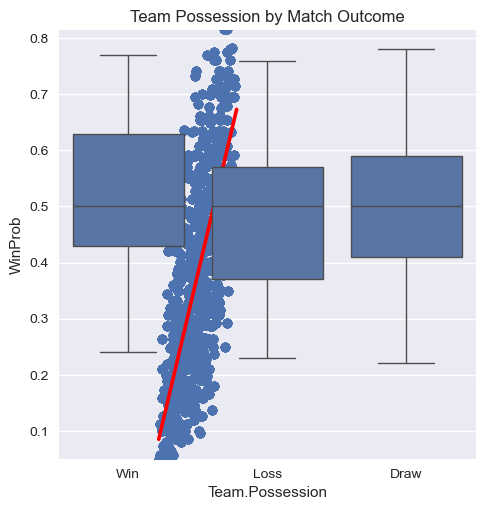

                            OLS Regression Results                            
Dep. Variable:                WinProb   R-squared:                       0.506
Model:                            OLS   Adj. R-squared:                  0.506
Method:                 Least Squares   F-statistic:                     9298.
Date:                Sat, 07 Jun 2025   Prob (F-statistic):               0.00
Time:                        20:16:49   Log-Likelihood:                 5205.8
No. Observations:                9094   AIC:                        -1.041e+04
Df Residuals:                    9092   BIC:                        -1.039e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              -0.1464      0.006    -

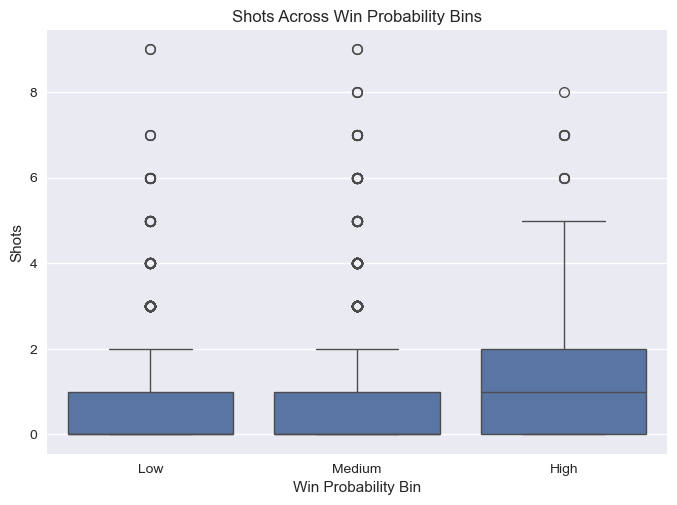


Analysis 3: Team Shooting vs Goals


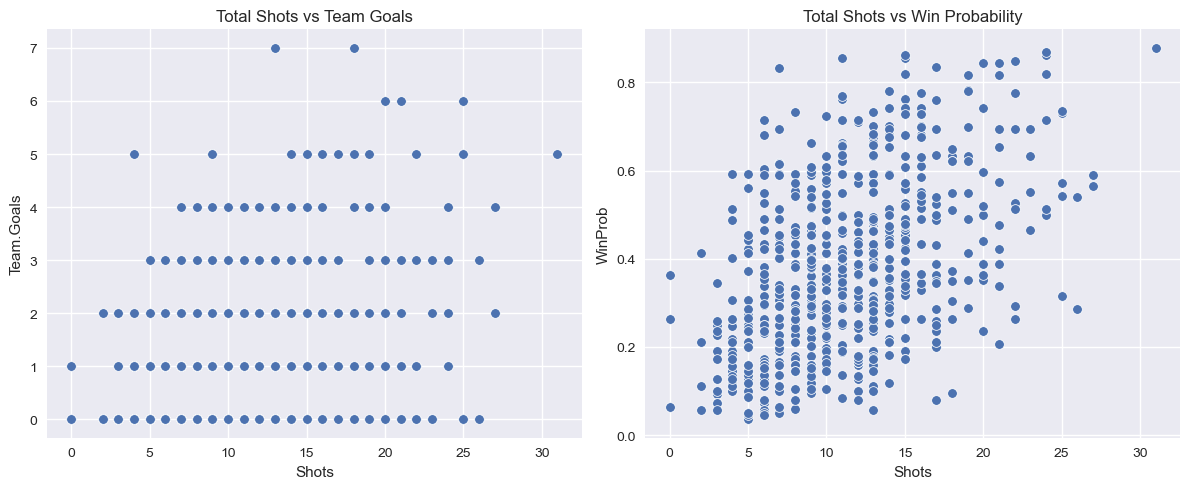


Analysis 4: Shot Timing Distribution


C:\Users\user\AppData\Local\Temp\ipykernel_9448\818517761.py:140: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  minute_dist = df.groupby('MinuteBin')['Shots'].sum().reset_index()


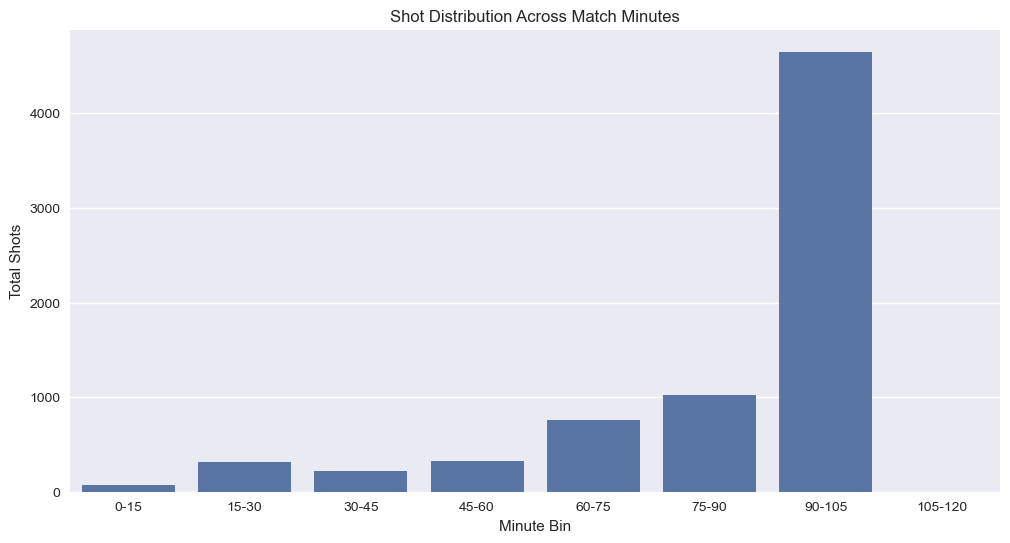

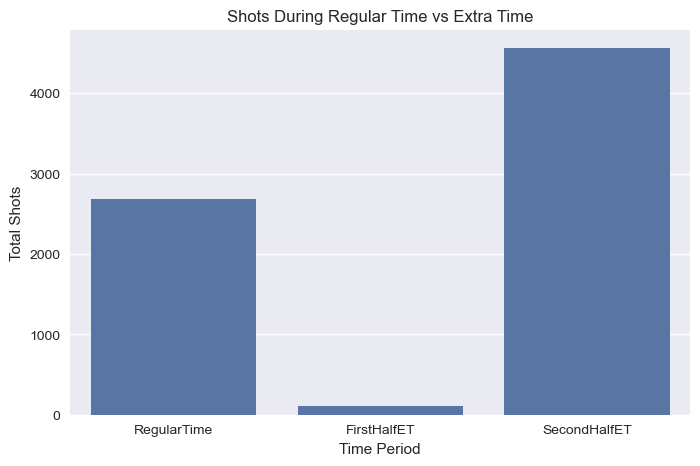


Analysis 5: Shots vs Win Probability


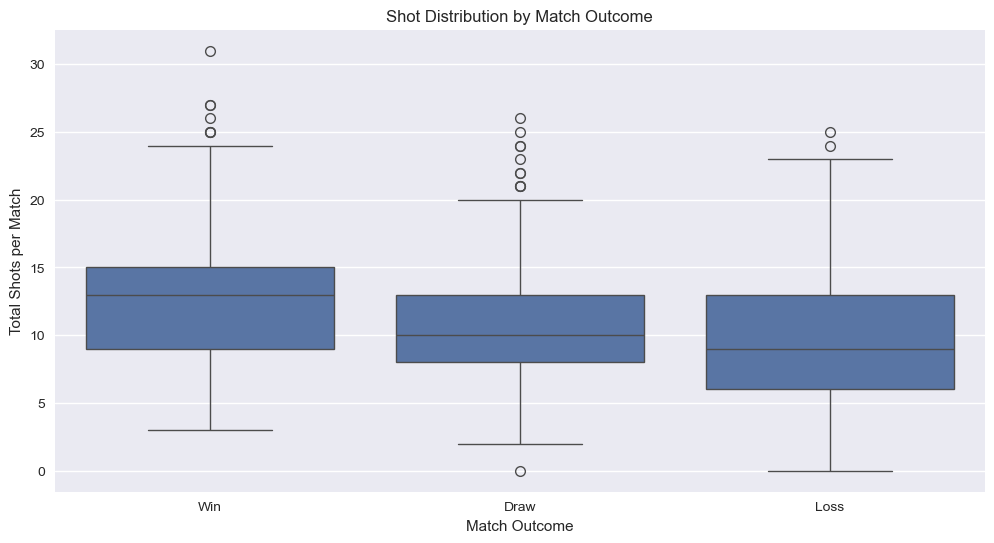


Analysis 6: Home vs Away Shooting


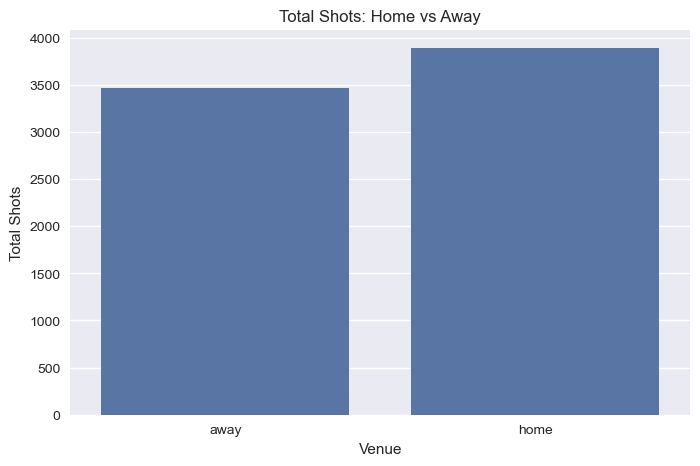


T-test for Home vs Away Shots: t-statistic = 3.99, p-value = 0.0001

Position-specific Home/Away Differences:


HmAw,away,home
PlyPosition,,
AMC,1.557971,1.558824
AML,1.776119,1.943182
AMR,1.417910,1.681818
DC,0.428951,0.521563
DL,0.476000,0.420233
DMC,0.654545,0.678392
DML,0.584615,0.724138
DMR,0.615385,0.603448
DR,0.376000,0.439689


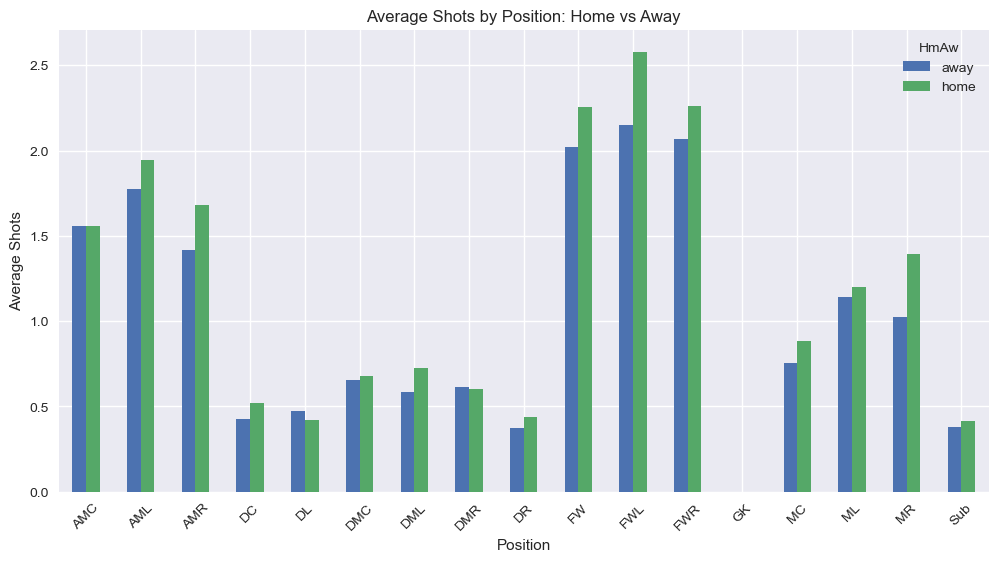


Top 10 Shooters:
Player
Mohamed Salah                    115
Dominic Calvert Lewin             92
Sadio Mane                        78
Roberto Firmino                   77
Raul Jimenez                      74
Jack Grealish                     70
Harry Kane                        69
Bruno Miguel Borges Fernandes     69
Jamie Vardy                       69
Neal Maupay                       67
Name: Shots, dtype: int64


In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

# Set up visualization style
plt.style.use('seaborn-v0_8')  # Updated style name
%matplotlib inline

# Load the data
file_path = "train.csv"  # Kaggle: Predict Shots in the Premier League
try:
    df = pd.read_csv(file_path, encoding='latin1')
    print("Data loaded successfully. Shape:", df.shape)
except Exception as e:
    print("Error loading data:", e)

# Display basic info
print("\nData Info:")
print(df.info())

# Display missing data info
print("\nMissing Values:")
display(df.isnull().sum().sort_values(ascending=False).head(10))

# Display first few rows
print("\nSample Data:")
display(df.head())

# Data Cleaning and Preparation
# Convert Date to datetime
df['Date'] = pd.to_datetime(df['Date'], format='%Y-%m-%d')  # Added format for your date style

# Create minute bins (15-minute intervals)
bins = [0, 15, 30, 45, 60, 75, 90, 105, 120]
labels = ['0-15', '15-30', '30-45', '45-60', '60-75', '75-90', '90-105', '105-120']
df['MinuteBin'] = pd.cut(df['Minutes'], bins=bins, labels=labels, right=False)

# Create extra time indicator
df['IsExtraTime'] = np.where((df['Minutes'] > 45) & (df['Minutes'] <= 50), 'FirstHalfET',
                            np.where(df['Minutes'] > 90, 'SecondHalfET', 'RegularTime'))

# Create match outcome
df['Outcome'] = np.where(df['Team.Goals'] > df['Opponent.Goals'], 'Win',
                        np.where(df['Team.Goals'] == df['Opponent.Goals'], 'Draw', 'Loss'))

# Outcome distribution plot
sns.countplot(x='Outcome', data=df, order=['Win', 'Draw', 'Loss'])
plt.title('Match Outcomes Distribution')
plt.show()

# Analysis 1: Which positions take the most shots?
print("\nAnalysis 1: Shots by Position")
position_shots = df.groupby('PlyPosition')['Shots'].agg(['sum', 'mean', 'count'])
position_shots = position_shots.sort_values('sum', ascending=False)
display(position_shots)

# Plot
plt.figure(figsize=(12, 6))
ax = sns.barplot(x=position_shots.index, y='sum', data=position_shots)
plt.title('Total Shots by Position')
plt.xlabel('Position')
plt.ylabel('Total Shots')
plt.xticks(rotation=45)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', label_type='edge', fontsize=8)
plt.show()

# Analysis 2: Does team possession relate to player shots?
print("\nAnalysis 2: Possession vs Shots")
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Team.Possession', y='Shots', data=df, hue='PlyPosition')
plt.title('Team Possession vs Player Shots')
plt.xlabel('Team Possession (%)')
plt.ylabel('Shots')
plt.show()

# Calculate correlation
corr = df[['Team.Possession', 'Shots']].corr()
print("\nCorrelation between Possession and Shots:")
display(corr)

# Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df.select_dtypes(include=[np.number]).corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

#possesion and win prob has a .71 correlation
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Team.Possession', y='WinProb', data=df)
plt.title('Team Possession vs Win Probability')
plt.xlabel('Possession (%)')
plt.ylabel('Win Probability')
plt.show()
sns.lmplot(x='Team.Possession', y='WinProb', data=df, line_kws={'color': 'red'})

#does winning teams have more possesion:
sns.boxplot(x='Outcome', y='Team.Possession', data=df)
plt.title('Team Possession by Match Outcome')
plt.show()

#regression Model
import statsmodels.api as sm
X = df[['Team.Possession']]
X = sm.add_constant(X)
y = df['WinProb']
model = sm.OLS(y, X).fit()
print(model.summary())


# Win probability binning
df['WinProbBin'] = pd.cut(df['WinProb'], bins=[0, 0.33, 0.66, 1.01], labels=['Low', 'Medium', 'High'])
sns.boxplot(x='WinProbBin', y='Shots', data=df)
plt.title('Shots Across Win Probability Bins')
plt.xlabel('Win Probability Bin')
plt.ylabel('Shots')
plt.show()

# Analysis 3: Do teams that shoot more score more?
print("\nAnalysis 3: Team Shooting vs Goals")
team_shooting = df.groupby(['Team', 'Date']).agg({'Shots': 'sum', 'Team.Goals': 'mean', 'WinProb': 'mean'}).reset_index()

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.scatterplot(x='Shots', y='Team.Goals', data=team_shooting)
plt.title('Total Shots vs Team Goals')

plt.subplot(1, 2, 2)
sns.scatterplot(x='Shots', y='WinProb', data=team_shooting)
plt.title('Total Shots vs Win Probability')
plt.tight_layout()
plt.show()

# Analysis 4: When do shots happen most often?
print("\nAnalysis 4: Shot Timing Distribution")
minute_dist = df.groupby('MinuteBin')['Shots'].sum().reset_index()

plt.figure(figsize=(12, 6))
sns.barplot(x='MinuteBin', y='Shots', data=minute_dist, order=labels)
plt.title('Shot Distribution Across Match Minutes')
plt.xlabel('Minute Bin')
plt.ylabel('Total Shots')
plt.show()

# Extra time analysis
et_shots = df.groupby('IsExtraTime')['Shots'].sum().reset_index()
plt.figure(figsize=(8, 5))
sns.barplot(x='IsExtraTime', y='Shots', data=et_shots, order=['RegularTime', 'FirstHalfET', 'SecondHalfET'])
plt.title('Shots During Regular Time vs Extra Time')
plt.xlabel('Time Period')
plt.ylabel('Total Shots')
plt.show()

# Analysis 5: Do more shots lead to higher win probability?
print("\nAnalysis 5: Shots vs Win Probability")
match_level = df.groupby(['Team', 'Date', 'Outcome']).agg({'Shots': 'sum', 'WinProb': 'mean'}).reset_index()

plt.figure(figsize=(12, 6))
sns.boxplot(x='Outcome', y='Shots', data=match_level, order=['Win', 'Draw', 'Loss'])
plt.title('Shot Distribution by Match Outcome')
plt.xlabel('Match Outcome')
plt.ylabel('Total Shots per Match')
plt.show()

# Analysis 6: Home vs Away shooting
print("\nAnalysis 6: Home vs Away Shooting")
home_away = df.groupby('HmAw')['Shots'].agg(['sum', 'mean', 'count'])

plt.figure(figsize=(8, 5))
sns.barplot(x=home_away.index, y='sum', data=home_away)
plt.title('Total Shots: Home vs Away')
plt.xlabel('Venue')
plt.ylabel('Total Shots')
plt.show()

# Statistical test for home vs away
home_shots = df[df['HmAw'] == 'home']['Shots']
away_shots = df[df['HmAw'] == 'away']['Shots']
t_stat, p_value = stats.ttest_ind(home_shots, away_shots, equal_var=False)
print(f"\nT-test for Home vs Away Shots: t-statistic = {t_stat:.2f}, p-value = {p_value:.4f}")

# Additional Analysis: Position-specific home/away differences
print("\nPosition-specific Home/Away Differences:")
position_ha = df.groupby(['PlyPosition', 'HmAw'])['Shots'].mean().unstack()
display(position_ha)

position_ha.plot(kind='bar', figsize=(12, 6))
plt.title('Average Shots by Position: Home vs Away')
plt.xlabel('Position')
plt.ylabel('Average Shots')
plt.xticks(rotation=45)
plt.show()

# Player-level summary: Top shooters
top_shooters = df.groupby('Player')['Shots'].sum().sort_values(ascending=False).head(10)
print("\nTop 10 Shooters:")
print(top_shooters)


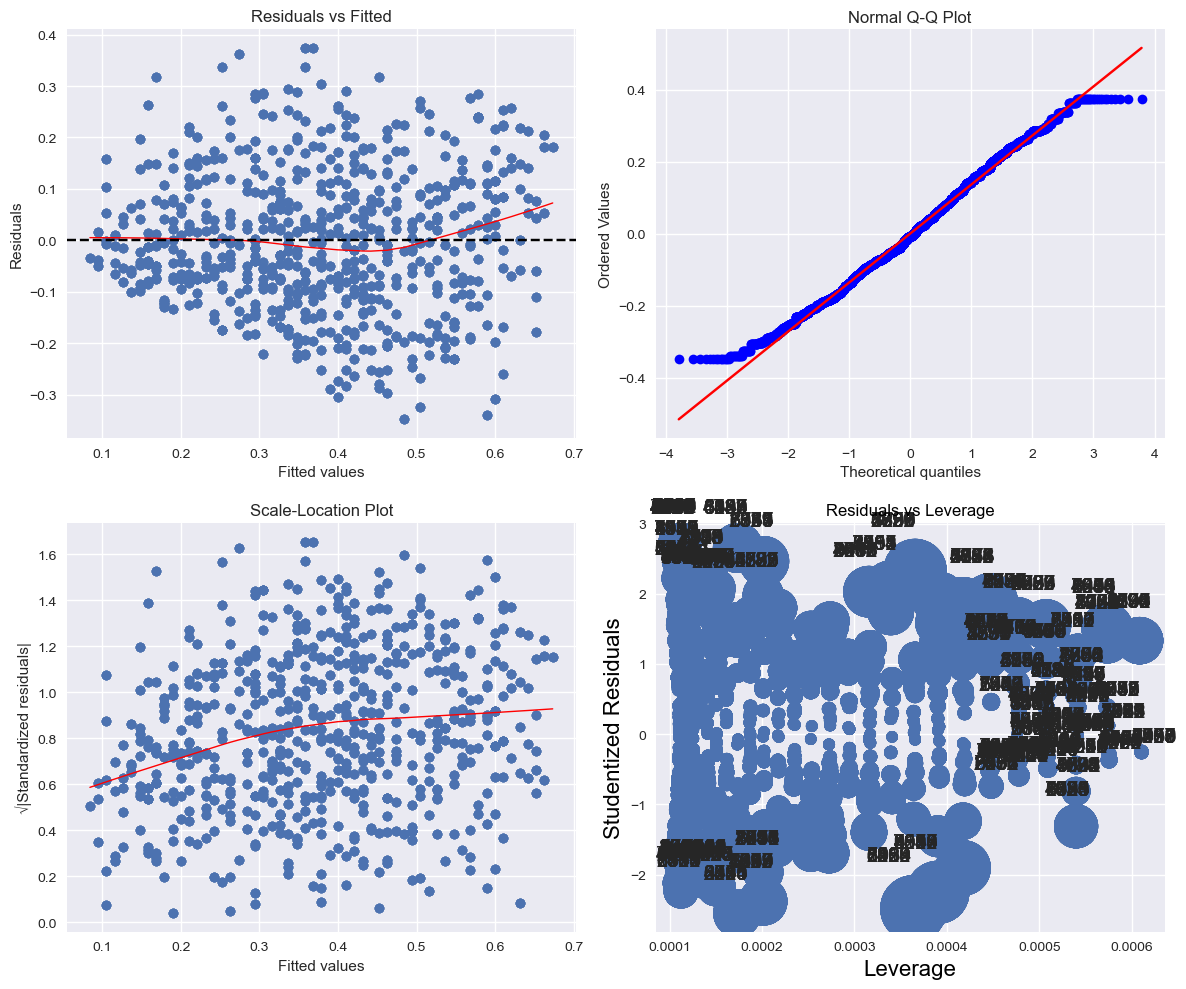


=== Statistical Tests for Assumptions ===
Normality Tests:
Jarque-Bera: statistic=87.792, p-value=0.0000
Anderson-Darling: statistic=12.394, p-value=0.0000

Heteroscedasticity Test (Breusch-Pagan):
Lagrange multiplier: 274.853, p-value: 0.0000

Variance Inflation Factors (VIF):
{'Team.Possession': 1.0}

Durbin-Watson statistic: 1.504
Interpretation:
1.5-2.5: No autocorrelation
<1.5: Positive autocorrelation
>2.5: Negative autocorrelation

=== Assumption Check Summary ===
1. LINEARITY: Check Residuals vs Fitted plot - points should be randomly scattered
2. NORMALITY: Check Q-Q plot - points should follow the line
3. HOMOSCEDASTICITY: Check Scale-Location plot - spread should be even
4. NO INFLUENTIAL POINTS: Check Leverage plot - no points in upper/lower right

Note: With your large sample size (n=9094), small deviations from normality may not be problematic


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan, normal_ad
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats

# Assuming you've already run:
# X = sm.add_constant(df['Team.Possession'])
# model = sm.OLS(df['WinProb'], X).fit()

# Get residuals and fitted values
fitted_values = model.fittedvalues
residuals = model.resid
standardized_residuals = model.get_influence().resid_studentized_internal

# Set up diagnostic plots
plt.figure(figsize=(12, 10))

# 1. Residuals vs Fitted
plt.subplot(2, 2, 1)
sns.regplot(x=fitted_values, y=residuals, lowess=True,
            line_kws={'color': 'red', 'lw': 1},
            scatter_kws={'alpha': 0.3})
plt.axhline(y=0, color='k', linestyle='--')
plt.title('Residuals vs Fitted')
plt.xlabel('Fitted values')
plt.ylabel('Residuals')

# 2. Q-Q Plot
plt.subplot(2, 2, 2)
stats.probplot(residuals, dist="norm", plot=plt)
plt.title('Normal Q-Q Plot')

# 3. Scale-Location Plot
plt.subplot(2, 2, 3)
sns.regplot(x=fitted_values, y=np.sqrt(np.abs(standardized_residuals)), lowess=True,
            line_kws={'color': 'red', 'lw': 1},
            scatter_kws={'alpha': 0.3})
plt.title('Scale-Location Plot')
plt.xlabel('Fitted values')
plt.ylabel('√|Standardized residuals|')

# 4. Residuals vs Leverage
plt.subplot(2, 2, 4)
sm.graphics.influence_plot(model, ax=plt.gca(), criterion="cooks")
plt.title('Residuals vs Leverage')

plt.tight_layout()
plt.show()

# Statistical tests
print("\n=== Statistical Tests for Assumptions ===")

# 1. Normality Tests
jb_test = stats.jarque_bera(residuals)
ad_test = normal_ad(residuals)
print("Normality Tests:")
print(f"Jarque-Bera: statistic={jb_test[0]:.3f}, p-value={jb_test[1]:.4f}")
print(f"Anderson-Darling: statistic={ad_test[0]:.3f}, p-value={ad_test[1]:.4f}")

# 2. Heteroscedasticity Test
bp_test = het_breuschpagan(residuals, model.model.exog)
print("\nHeteroscedasticity Test (Breusch-Pagan):")
print(f"Lagrange multiplier: {bp_test[0]:.3f}, p-value: {bp_test[1]:.4f}")

# 3. Multicollinearity (VIF)
print("\nVariance Inflation Factors (VIF):")
if len(model.model.exog_names) > 1:
    vif = [variance_inflation_factor(model.model.exog, i) 
           for i in range(1, model.model.exog.shape[1])]  # Skip intercept
    print(dict(zip(model.model.exog_names[1:], vif)))
else:
    print("Only one predictor - VIF not applicable")

# 4. Autocorrelation
dw_stat = sm.stats.stattools.durbin_watson(residuals)
print(f"\nDurbin-Watson statistic: {dw_stat:.3f}")
print("Interpretation:")
print("1.5-2.5: No autocorrelation\n<1.5: Positive autocorrelation\n>2.5: Negative autocorrelation")

# Interpretation guide
print("\n=== Assumption Check Summary ===")
print("1. LINEARITY: Check Residuals vs Fitted plot - points should be randomly scattered")
print("2. NORMALITY: Check Q-Q plot - points should follow the line")
print("3. HOMOSCEDASTICITY: Check Scale-Location plot - spread should be even")
print("4. NO INFLUENTIAL POINTS: Check Leverage plot - no points in upper/lower right")
print("\nNote: With your large sample size (n=9094), small deviations from normality may not be problematic")